
--- Team Efficiency Table ---
    rank                         team  efficiency_index
0      1               Mumbai Indians              0.38
5      1          Chennai Super Kings              0.38
7      2          Sunrisers Hyderabad              0.36
2      3        Kolkata Knight Riders              0.35
6      3             Rajasthan Royals              0.35
11     4      Rising Pune Supergiants              0.33
12     5         Kochi Tuskers Kerala              0.32
1      6  Royal Challengers Bangalore              0.31
3      7              Kings XI Punjab              0.30
4      8             Delhi Daredevils              0.28


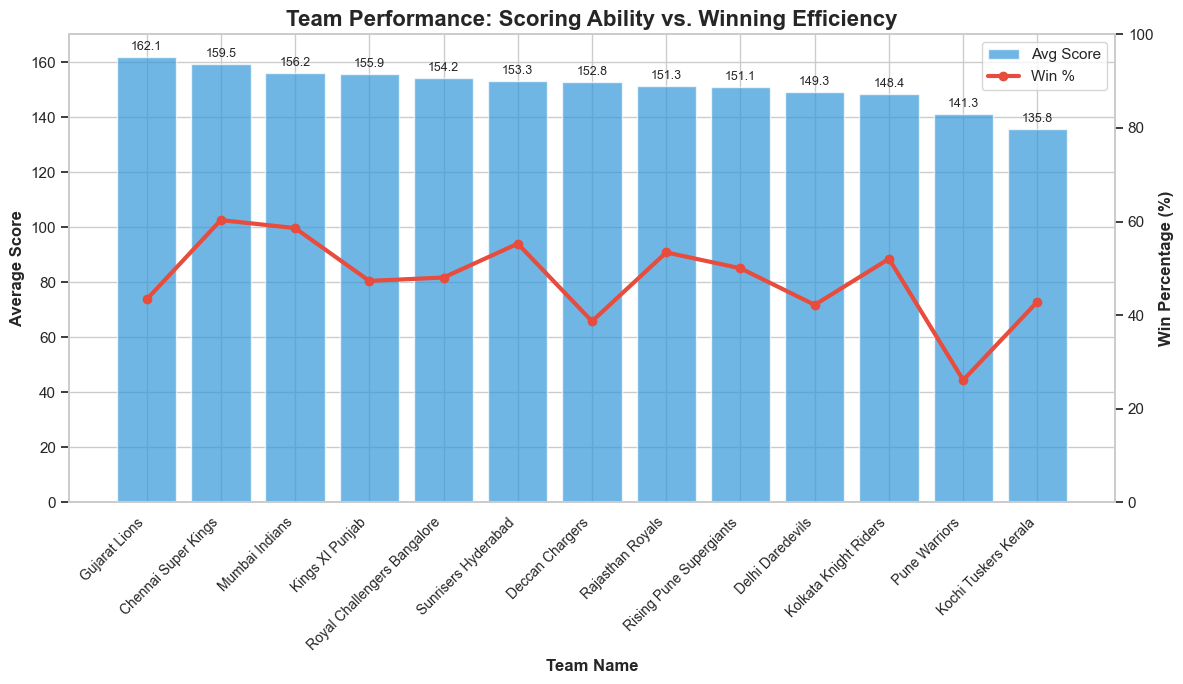

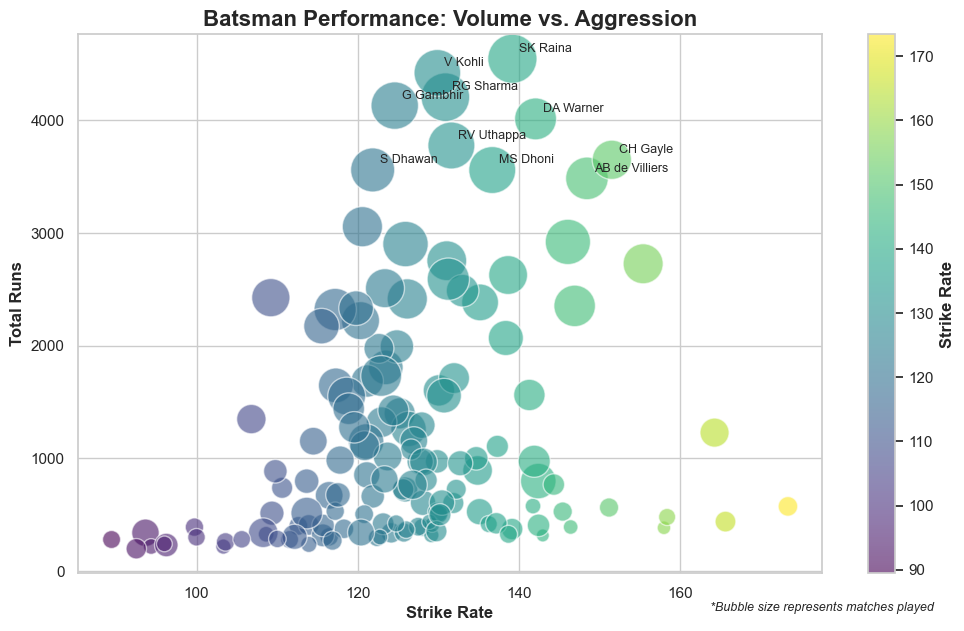

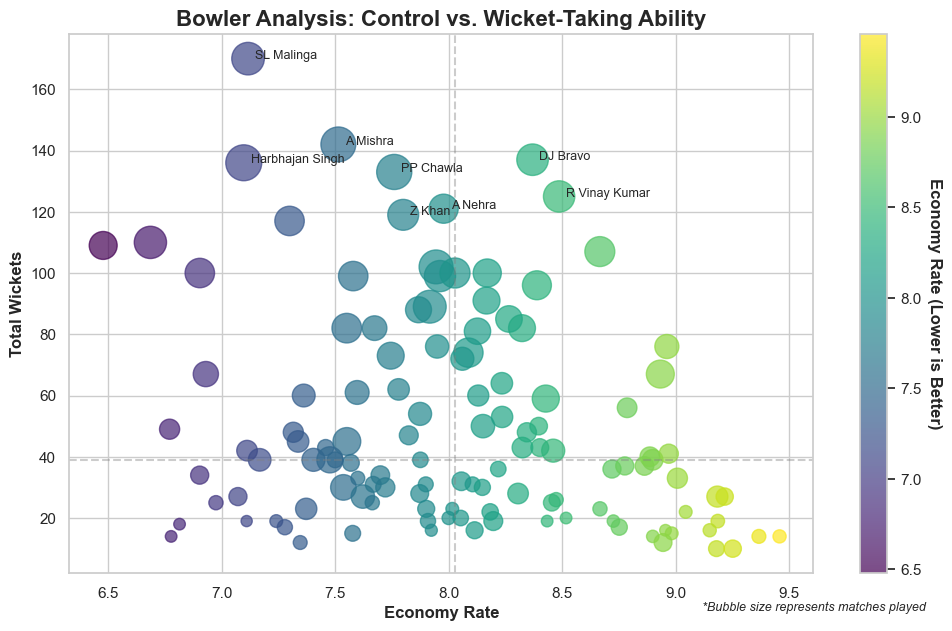

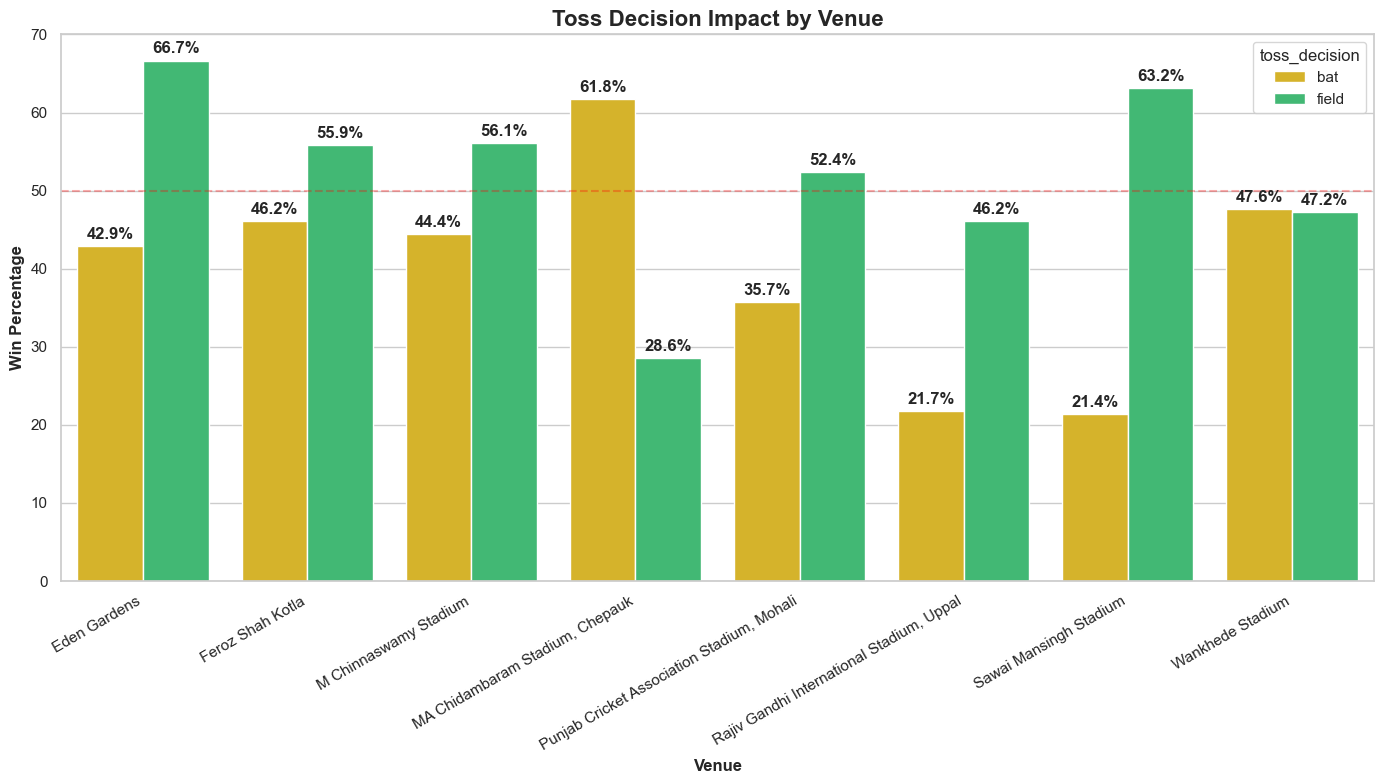

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

class CricketDataProcessor:
    """Handles data loading and common transformations."""
    def __init__(self, deliveries_path, matches_path):
        self.ball_df = pd.read_csv(deliveries_path)
        self.match_df = pd.read_csv(matches_path)
        self._apply_global_style()

    def _apply_global_style(self):
        """Sets a consistent professional aesthetic for all plots."""
        
        sns.set_theme(style="whitegrid")
        plt.rcParams.update({
            'figure.figsize': (12, 7),
            'axes.titlesize': 16,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'axes.labelweight': 'bold',
            'legend.frameon': True
        })

class CricketVisualizer:
    """Contains all plotting logic as independent modules."""

    @staticmethod
    def get_efficiency_metrics(processor):
        """Processes data for the efficiency table (Backend Logic)."""
        # 1. Matches & Wins
        m_played = pd.concat([processor.match_df['team1'], processor.match_df['team2']]).value_counts().reset_index()
        m_played.columns = ['team', 'matches']
        
        wins = processor.match_df['winner'].value_counts().reset_index()
        wins.columns = ['team', 'wins']
        
        df = m_played.merge(wins, on='team', how='left').fillna(0)
        df['win_percentage'] = (df['wins'] / df['matches']) * 100

        # 2. Avg Scores
        team_runs = processor.ball_df.groupby(['match_id', 'batting_team'])['total_runs'].sum().reset_index()
        avg_score = team_runs.groupby('batting_team')['total_runs'].mean().reset_index()
        avg_score.columns = ['team', 'avg_score'] 
        
        df = df.merge(avg_score, on='team')

        # 3. Death Over Pressure (Overs 16-20)
        pressure_df = processor.ball_df[processor.ball_df['over'] > 15]
        p_avg_runs = pressure_df.groupby(['match_id', 'batting_team'])['total_runs'].sum().reset_index()
        p_avg = p_avg_runs.groupby('batting_team')['total_runs'].mean().reset_index()
        p_avg.columns = ['team', 'pressure_avg_runs']
        
        df = df.merge(p_avg, on='team')

        # 4. Indices & Ranking
        df['efficiency_index'] = (df['win_percentage'] / df['avg_score']).round(2)
        df['rank'] = df['efficiency_index'].rank(ascending=False, method='dense').astype(int)
        
        return df.sort_values(by='rank').round(2)

    @staticmethod
    def save_table_as_png(df, processor, filename="team_efficiency.png"):
        """Exports the efficiency dataframe as a styled PNG image."""
        # Selecting final columns for display
        display_df = df[['rank', 'team', 'avg_score', 'pressure_avg_runs', 'win_percentage', 'efficiency_index']]

        fig, ax = plt.subplots(figsize=(14, 6))
        ax.axis('off')

        table = ax.table(
            cellText=display_df.values,
            colLabels=display_df.columns,
            loc='center',
            cellLoc='center'
        )

        table.auto_set_font_size(False)
        table.set_fontsize(10)
        table.scale(1, 1.8)

        for (row, col), cell in table.get_celld().items():
            if row == 0:
                cell.set_facecolor('#2E86C1')
                cell.set_text_props(weight='bold', color='white')
            else:
                cell.set_facecolor('#F4F6F7')

        plt.title("Team Efficiency & Pressure Performance Report", fontsize=16, weight='bold', pad=20)
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.close()
        
    @staticmethod
    def plot_team_performance(processor):
        """Figure 1: Scoring vs Win %"""
        # --- FIX: Safe column mapping for matches played ---
        m_played = pd.concat([processor.match_df['team1'], processor.match_df['team2']]).value_counts().reset_index()
        
        # This handles different Pandas versions dynamically
        m_played.columns = ['team', 'matches'] 
        
        # --- FIX: Safe column mapping for wins ---
        wins_raw = processor.match_df['winner'].value_counts().reset_index()
        
        # Explicitly renaming to 'team' and 'wins' regardless of default names
        wins_raw.columns = ['team', 'wins']
        
        # Now the merge will work because 'team' is guaranteed to exist in both
        team_stats = m_played.merge(wins_raw, on='team', how='left').fillna(0)
        
        team_stats['win_percentage'] = (team_stats['wins'] / team_stats['matches']) * 100
        team_runs = processor.ball_df.groupby(['match_id', 'batting_team'])['total_runs'].sum().reset_index()
        avg_score = team_runs.groupby('batting_team')['total_runs'].mean().reset_index(name='avg_score')
        
        df = team_stats.merge(avg_score, left_on='team', right_on='batting_team').sort_values('avg_score', ascending=False)

        # Plotting
        fig, ax1 = plt.subplots()
        bars = ax1.bar(df['team'], df['avg_score'], color='#3498db', alpha=0.7, label='Avg Score')
        ax1.set_ylabel('Average Score')
        plt.setp(ax1.get_xticklabels(), rotation=30, horizontalalignment='right', fontsize=10)

        ax1.tick_params(axis='x', rotation=45)
        ax1.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)

        ax2 = ax1.twinx()
        ax2.plot(df['team'], df['win_percentage'], color='#e74c3c', marker='o', linewidth=3, label='Win %')
        ax2.set_ylabel('Win Percentage (%)')
        ax2.set_ylim(0, 100)
        ax2.grid(False)
        
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, loc='upper right', frameon=True)

        plt.title('Team Performance: Scoring Ability vs. Winning Efficiency')
        ax1.set_xlabel("Team Name")
        plt.tight_layout()
        plt.savefig('1_team_performance.png', dpi=300, bbox_inches='tight')
        plt.show()

    @staticmethod
    def plot_batsman_bubble(processor, min_balls=200):
        """Figure 2: Strike Rate vs Runs Bubble Chart"""
        valid = processor.ball_df[processor.ball_df['wide_runs'] == 0]
        stats = valid.groupby('batsman').agg({'batsman_runs': 'sum', 'ball': 'count', 'match_id': 'nunique'}).reset_index()
        stats.columns = ['batsman', 'total_runs', 'balls_faced', 'matches']
        
        stats['strike_rate'] = (stats['total_runs'] / stats['balls_faced']) * 100
        stats = stats[stats['balls_faced'] > min_balls]

        fig, ax = plt.subplots()
        scatter = ax.scatter(stats['strike_rate'], stats['total_runs'], 
                           s=stats['matches'] * 8, c=stats['strike_rate'], 
                           cmap='viridis', alpha=0.6, edgecolors="white")
        
        # Annotate Top 10
        top = stats.nlargest(10, 'total_runs')
        for _, row in top.iterrows():
            ax.annotate(row['batsman'], (row['strike_rate'], row['total_runs']), xytext=(5,5), textcoords='offset points', fontsize=9)

        plt.text(0.85, -0.07, "*Bubble size represents matches played", 
             transform=ax.transAxes, fontsize=9, style='italic')
        
        plt.colorbar(scatter, label='Strike Rate')
        plt.title("Batsman Performance: Volume vs. Aggression")
        plt.xlabel("Strike Rate")
        plt.ylabel("Total Runs")
        plt.savefig('2_batsman_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()

    @staticmethod
    def plot_bowler_quadrants(processor, min_balls=300):
        """Figure 3: Economy vs Wickets Quadrant Chart"""
        runs = processor.ball_df.groupby('bowler').agg({'total_runs':'sum','match_id':'nunique'}).reset_index()
        valid = processor.ball_df[(processor.ball_df['wide_runs'] == 0) & (processor.ball_df['noball_runs'] == 0)]
        balls = valid.groupby('bowler')['ball'].count().reset_index(name='balls')
        wickets = processor.ball_df[processor.ball_df['player_dismissed'].notnull()].groupby('bowler').size().reset_index(name='wickets')
        runs.columns=['bowler','total_runs','matches']
        stats = runs.merge(balls, on='bowler').merge(wickets, on='bowler', how='left').fillna(0)
        stats['economy'] = (stats['total_runs'] / stats['balls']) * 6
        stats = stats[stats['balls'] > min_balls]
        fig, ax = plt.subplots()
        scatter = ax.scatter(stats['economy'], stats['wickets'],s=stats['matches'] * 5, c=stats['economy'], cmap='viridis', alpha=0.7)

        cbar = fig.colorbar(scatter, ax=ax)
        cbar.set_label('Economy Rate (Lower is Better)', rotation=270, labelpad=15)
        
        # Quadrant Lines
        ax.axhline(stats['wickets'].median(), color='gray', linestyle='--', alpha=0.4)
        ax.axvline(stats['economy'].mean(), color='gray', linestyle='--', alpha=0.4)

        # Labeling
        top = stats.nlargest(8, 'wickets')
        for _, row in top.iterrows():
            ax.annotate(row['bowler'], (row['economy'], row['wickets']), xytext=(5,0), textcoords='offset points', fontsize=9)

            
        plt.text(0.85, -0.07, "*Bubble size represents matches played", 
             transform=ax.transAxes, fontsize=9, style='italic')
        plt.title("Bowler Analysis: Control vs. Wicket-Taking Ability")
        plt.xlabel("Economy Rate")
        plt.ylabel("Total Wickets")
        plt.savefig('3_bowler_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()

    @staticmethod
    def plot_toss_impact(processor, top_n=8):
        """Figure 4: Toss Decision Impact per Venue"""
        df = processor.match_df.copy()
        df['toss_win_match_win'] = (df['toss_winner'] == df['winner'])
        
        top_venues = df['venue'].value_counts().head(top_n).index
        filtered = df[df['venue'].isin(top_venues)]
        
        grouped = filtered.groupby(['venue', 'toss_decision'])['toss_win_match_win'].mean().reset_index()
        grouped['win_percentage'] = grouped['toss_win_match_win'] * 100

        
        
        plt.figure(figsize=(14, 8))
        plot = sns.barplot(data=grouped, x='venue', y='win_percentage', hue='toss_decision', palette={"bat": "#f1c40f", "field": "#2ecc71"})
        
        for container in plot.containers:
            plot.bar_label(container, fmt='%.1f%%', padding=3, fontweight='bold')
        
        
        plt.axhline(50, color='red', linestyle='--', alpha=0.3)
        plt.title('Toss Decision Impact by Venue')
        plt.xlabel('Venue')
        plt.ylabel('Win Percentage')
        plt.xticks(rotation=30, ha='right')
        plt.tight_layout()
        plt.savefig('4_toss_impact.png', dpi=300, bbox_inches='tight')
        plt.show()

# --- EXECUTION ---
if __name__ == "__main__":
    # Initialize Processor
    data = CricketDataProcessor("deliveries.csv", "matches.csv")
    viz = CricketVisualizer()

    efficiency_table = viz.get_efficiency_metrics(data)
    print("\n--- Team Efficiency Table ---")
    print(efficiency_table[['rank', 'team', 'efficiency_index']].head(10))

    # 3. Save Table as PNG
    viz.save_table_as_png(efficiency_table, data)
    
    # Run Visuals
    viz = CricketVisualizer()
    viz.plot_team_performance(data)
    viz.plot_batsman_bubble(data)
    viz.plot_bowler_quadrants(data)
    viz.plot_toss_impact(data)